# Inflação e Comunicação do Copom — Notebook Completo e Reprodutível

Este notebook consolida de forma **autocontida, modificável e visualizável** todas as **7 etapas obrigatórias** definidas em `projeto.md`:

1. **Estrutura de painel (Etapa 7):** 16 regiões/capitais × 9 grupos de despesa × 177 meses (jan/2012–set/2026) + dicionário de variáveis.
2. **Análise exploratória — EDA (Etapa 1):** estatísticas descritivas, ausentes, outliers (1,5 × IQR), decomposição STL, ADF/KPSS e ACF/PACF.
3. **Análise de correlação (Etapa 2):** matrizes de Pearson/Spearman, CCF com defasagens, causalidade de Granger, VIF e conclusão obrigatória de seleção.
4. **Predição multivariada e validação temporal (Etapas 3 e 4):** walk-forward (origem móvel, $h = 1, 2, 3$ meses) comparando Focus, Naïve Sazonal, VAR, SARIMAX, Ridge, Random Forest e LSTM — na série nacional e no painel completo (`16 áreas × 9 grupos`).
5. **Métricas, Diebold-Mariano e intervalos de previsão (Etapa 5):** MAE, RMSE, MAPE, sMAPE, MASE, teste de Diebold-Mariano e bandas de 80% e 95%.
6. **Análise de sentimento do Copom com LLM (Etapa 6):** corpus oficial do BCB (238 documentos), escores LLM (`rotulo_llm.json`), kappa de Cohen e impacto no SARIMAX walk-forward.

> **Como modificar e experimentar:** ajuste os parâmetros na **Seção 0** (área/grupo analisados, defasagens, hiperparâmetros dos modelos ou flags `REEXECUTAR_* = True`) e execute novamente as células.


## 0. Configuração e Hiperparâmetros Modificáveis

Edite as variáveis abaixo para inspecionar outras regiões/grupos ou alterar hiperparâmetros e reexecutar a modelagem ao vivo dentro do notebook.


In [1]:
from pathlib import Path
import warnings

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display
from scipy import stats
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tsa.api import VAR
from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.stattools import adfuller, grangercausalitytests, kpss
import statsmodels.api as sm
from torch import nn

warnings.filterwarnings("ignore")
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.25
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 140)

# Resolve raiz do projeto independentemente do diretório de trabalho
ROOT = Path.cwd().resolve()
if not (ROOT / "dados" / "tratados").exists():
    ROOT = ROOT.parent
DATA_DIR = ROOT / "dados" / "tratados"

# ==============================================================================
# PARÂMETROS MODIFICÁVEIS PELO USUÁRIO
# ==============================================================================
AREA_EXEMPLO = "São Paulo - SP"
GRUPO_EXEMPLO = "Alimentação e bebidas"

HORIZONTES = [1, 2, 3]
MESES_TESTE = 12
MAX_LAG_CCF = 12
MAX_LAG_GRANGER = 6

# Hiperparâmetros dos modelos (usados ao definir REEXECUTAR_MODELAGEM = True)
ALPHA_RIDGE = 10.0
RF_N_ESTIMATORS = 200
RF_MAX_DEPTH = 6
LSTM_LOOKBACK = 12
LSTM_EPOCHS = 120

# Flags de reexecução ao vivo (False = leitura rápida dos resultados validados)
REEXECUTAR_ANALISE_CORRELACAO = False
REEXECUTAR_MODELAGEM = False

print(f"Diretório de dados: {DATA_DIR}")
print(f"Série em foco: {AREA_EXEMPLO} | {GRUPO_EXEMPLO}")

Diretório de dados: C:\Users\rodri\Desktop\previsoes-Inflacao-comunicação-copom\dados\tratados
Série em foco: São Paulo - SP | Alimentação e bebidas


## 1. Estrutura de Painel e Dicionário de Variáveis (Etapa 7)

Carrega o painel tratado (`painel_ipca_macro.csv`), o dicionário das 14 colunas (`dicionario_painel_ipca_macro.csv`) e as expectativas de mercado Focus (`focus_expectativas.csv`).


In [2]:
painel = pd.read_csv(DATA_DIR / "painel_ipca_macro.csv", parse_dates=["data"], encoding="utf-8-sig")
macro = pd.read_csv(DATA_DIR / "macro_mensal.csv", parse_dates=["data"], encoding="utf-8-sig")
focus = pd.read_csv(
    DATA_DIR / "focus_expectativas.csv",
    parse_dates=["data_coleta", "mes_referencia"],
    encoding="utf-8-sig",
)
dicionario = pd.read_csv(DATA_DIR / "dicionario_painel_ipca_macro.csv", encoding="utf-8-sig")

print(
    f"Painel: {painel.shape[0]:,} linhas × {painel.shape[1]} colunas | "
    f"{painel['area'].nunique()} áreas × {painel['grupo_despesa'].nunique()} grupos × "
    f"{painel['data'].nunique()} meses ({painel['data'].min().strftime('%Y-%m')} a {painel['data'].max().strftime('%Y-%m')})"
)
print(f"Áreas disponíveis: {sorted(painel['area'].unique())}")
print(f"Grupos disponíveis: {sorted(painel['grupo_despesa'].unique())}")
display(dicionario[["variavel", "fonte", "unidade", "frequencia", "papel_no_painel"]])
display(painel.head(5))

Painel: 25,488 linhas × 14 colunas | 16 áreas × 9 grupos × 177 meses (2012-01 a 2026-09)
Áreas disponíveis: ['Aracaju - SE', 'Belo Horizonte - MG', 'Belém - PA', 'Brasília - DF', 'Campo Grande - MS', 'Curitiba - PR', 'Fortaleza - CE', 'Goiânia - GO', 'Grande Vitória - ES', 'Porto Alegre - RS', 'Recife - PE', 'Rio Branco - AC', 'Rio de Janeiro - RJ', 'Salvador - BA', 'São Luís - MA', 'São Paulo - SP']
Grupos disponíveis: ['Alimentação e bebidas', 'Artigos de residência', 'Comunicação', 'Despesas pessoais', 'Educação', 'Habitação', 'Saúde e cuidados pessoais', 'Transportes', 'Vestuário']


,variavel,fonte,unidade,frequencia,papel_no_painel
0,data,IBGE/SIDRA e Banco Central do Brasil,AAAA-MM-01 (data no primeiro dia do mês),mensal,Chave temporal e data de junção das fontes
1,area_id,IBGE/SIDRA,identificador categórico,mensal,Dimensão geográfica da chave do painel
2,area,IBGE/SIDRA,não se aplica,mensal,Descrição da dimensão geográfica
3,nivel_geografico,IBGE/SIDRA,categoria,mensal,Classificação da dimensão geográfica
4,grupo_id,IBGE/SIDRA,código categórico,mensal,Dimensão de grupo da chave do painel
5,grupo_despesa,IBGE/SIDRA,categoria,mensal,Descrição da dimensão de grupo
6,variacao_ipca_mensal_pct,IBGE/SIDRA,% ao mês,mensal,Alvo de inflação do painel
7,tabela_sidra,IBGE/SIDRA,código da tabela,mensal,Proveniência da observação
8,selic_efetiva_aa,Banco Central do Brasil (SGS),% a.a.,mensal,Variável macroeconômica nacional explicativa
9,cambio_usd_brl,Banco Central do Brasil (SGS),R$/US$,mensal,Variável macroeconômica nacional explicativa


,data,area_id,area,nivel_geografico,grupo_id,grupo_despesa,variacao_ipca_mensal_pct,tabela_sidra,selic_efetiva_aa,cambio_usd_brl,ic_br,ibc_br_sa,desocupacao,ipca_brasil
0,2012-01-01,2800308,Aracaju - SE,N6,7170,Alimentação e bebidas,NaN,1419,10.7,1.789,114.48,97.32318,NaN,0.56
1,2012-01-01,2800308,Aracaju - SE,N6,7445,Habitação,NaN,1419,10.7,1.789,114.48,97.32318,NaN,0.56
2,2012-01-01,2800308,Aracaju - SE,N6,7486,Artigos de residência,NaN,1419,10.7,1.789,114.48,97.32318,NaN,0.56
3,2012-01-01,2800308,Aracaju - SE,N6,7558,Vestuário,NaN,1419,10.7,1.789,114.48,97.32318,NaN,0.56
4,2012-01-01,2800308,Aracaju - SE,N6,7625,Transportes,NaN,1419,10.7,1.789,114.48,97.32318,NaN,0.56


## 2. Análise Exploratória — EDA (Etapa 1)

Apresenta as estatísticas descritivas por unidade, o perfil de valores ausentes (preservados sem imputação), a sinalização de outliers via `1,5 × IQR`, os testes conjuntos **ADF** e **KPSS** e a decomposição **STL** + **ACF/PACF** para a série escolhida em `AREA_EXEMPLO` e `GRUPO_EXEMPLO`.


In [3]:
resumo_desc = pd.read_csv(DATA_DIR / "resumo_descritivo_unidade_grupo.csv", encoding="utf-8-sig")
ausentes = pd.read_csv(DATA_DIR / "perfil_ausentes.csv", encoding="utf-8-sig")
outliers = pd.read_csv(DATA_DIR / "outliers_iqr.csv", parse_dates=["data"], encoding="utf-8-sig")
estacionariedade = pd.read_csv(DATA_DIR / "testes_estacionariedade.csv", encoding="utf-8-sig")

print(f"Séries avaliadas (área × grupo): {len(resumo_desc)}")
print(f"Total de valores ausentes no IPCA regional: {int(ausentes['n_ausentes'].sum()):,}")
print(f"Observações sinalizadas via 1,5 × IQR (mantidas na base): {len(outliers):,}")
print(
    f"Estacionariedade (5%): ADF rejeita raiz unitária em {(estacionariedade['adf_pvalor'] < 0.05).sum()}/{len(estacionariedade)} séries | "
    f"KPSS não rejeita estacionariedade em {(estacionariedade['kpss_pvalor'] >= 0.05).sum()}/{len(estacionariedade)} séries"
)

display(
    resumo_desc.groupby("grupo_despesa", as_index=False)[["media", "desvio_padrao", "minimo", "maximo"]]
    .mean()
    .round(3)
    .sort_values("media", ascending=False)
)
display(
    estacionariedade.loc[
        (estacionariedade["area"] == AREA_EXEMPLO) & (estacionariedade["grupo_despesa"] == GRUPO_EXEMPLO),
        ["area", "grupo_despesa", "n_observacoes", "adf_estatistica", "adf_pvalor", "adf_conclusao_5pct", "kpss_estatistica", "kpss_pvalor", "kpss_conclusao_5pct"],
    ]
)

Séries avaliadas (área × grupo): 144
Total de valores ausentes no IPCA regional: 2,487
Observações sinalizadas via 1,5 × IQR (mantidas na base): 1,239
Estacionariedade (5%): ADF rejeita raiz unitária em 104/144 séries | KPSS não rejeita estacionariedade em 134/144 séries


,grupo_despesa,media,desvio_padrao,minimo,maximo
0,Alimentação e bebidas,0.569,0.924,-1.492,3.688
4,Educação,0.523,1.477,-4.532,6.824
5,Habitação,0.496,1.381,-3.979,6.408
6,Saúde e cuidados pessoais,0.494,0.559,-1.380,2.468
3,Despesas pessoais,0.465,0.508,-1.067,2.744
7,Transportes,0.418,1.266,-5.184,4.460
8,Vestuário,0.363,0.839,-1.876,2.618
1,Artigos de residência,0.286,0.747,-2.020,2.369
2,Comunicação,0.113,0.545,-2.459,2.354


,area,grupo_despesa,n_observacoes,adf_estatistica,adf_pvalor,adf_conclusao_5pct,kpss_estatistica,kpss_pvalor,kpss_conclusao_5pct
63,São Paulo - SP,Alimentação e bebidas,177,-8.475779,1.436782e-13,estacionária (rejeita raiz unitária),0.118492,0.1,estacionária (não rejeita estacionariedade)


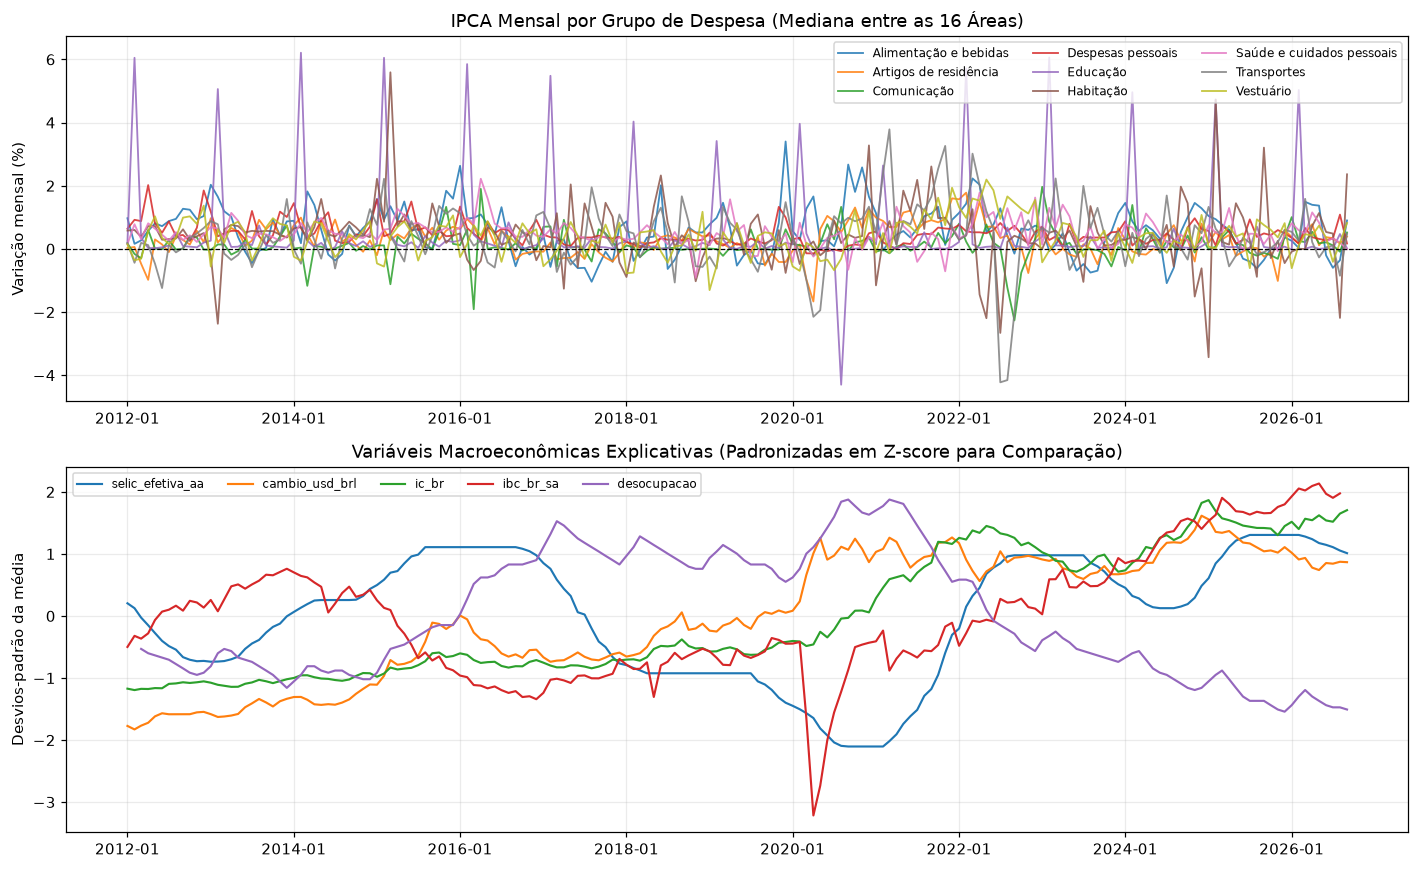

In [4]:
# Gráficos gerais das séries: IPCA por grupo (mediana entre áreas) e variáveis macroeconômicas
ipca_grupos = (
    painel.groupby(["data", "grupo_despesa"], as_index=False)["variacao_ipca_mensal_pct"]
    .median()
    .pivot(index="data", columns="grupo_despesa", values="variacao_ipca_mensal_pct")
)

fig, axes = plt.subplots(2, 1, figsize=(13, 8))
for col in ipca_grupos.columns:
    axes[0].plot(ipca_grupos.index, ipca_grupos[col], linewidth=1.2, alpha=0.85, label=col)
axes[0].axhline(0, color="black", linewidth=0.8, linestyle="--")
axes[0].set_title("IPCA Mensal por Grupo de Despesa (Mediana entre as 16 Áreas)")
axes[0].set_ylabel("Variação mensal (%)")
axes[0].legend(ncol=3, fontsize=8, loc="upper right")

macro_norm = macro.set_index("data")[["selic_efetiva_aa", "cambio_usd_brl", "ic_br", "ibc_br_sa", "desocupacao"]]
macro_z = (macro_norm - macro_norm.mean()) / macro_norm.std()
for col in macro_z.columns:
    axes[1].plot(macro_z.index, macro_z[col], linewidth=1.4, label=col)
axes[1].set_title("Variáveis Macroeconômicas Explicativas (Padronizadas em Z-score para Comparação)")
axes[1].set_ylabel("Desvios-padrão da média")
axes[1].legend(ncol=5, fontsize=8, loc="upper left")

for ax in axes:
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
plt.tight_layout()
plt.show()

Série selecionada: São Paulo - SP | Alimentação e bebidas (177 meses) -> ADF p=0.0000 | KPSS p=0.1000


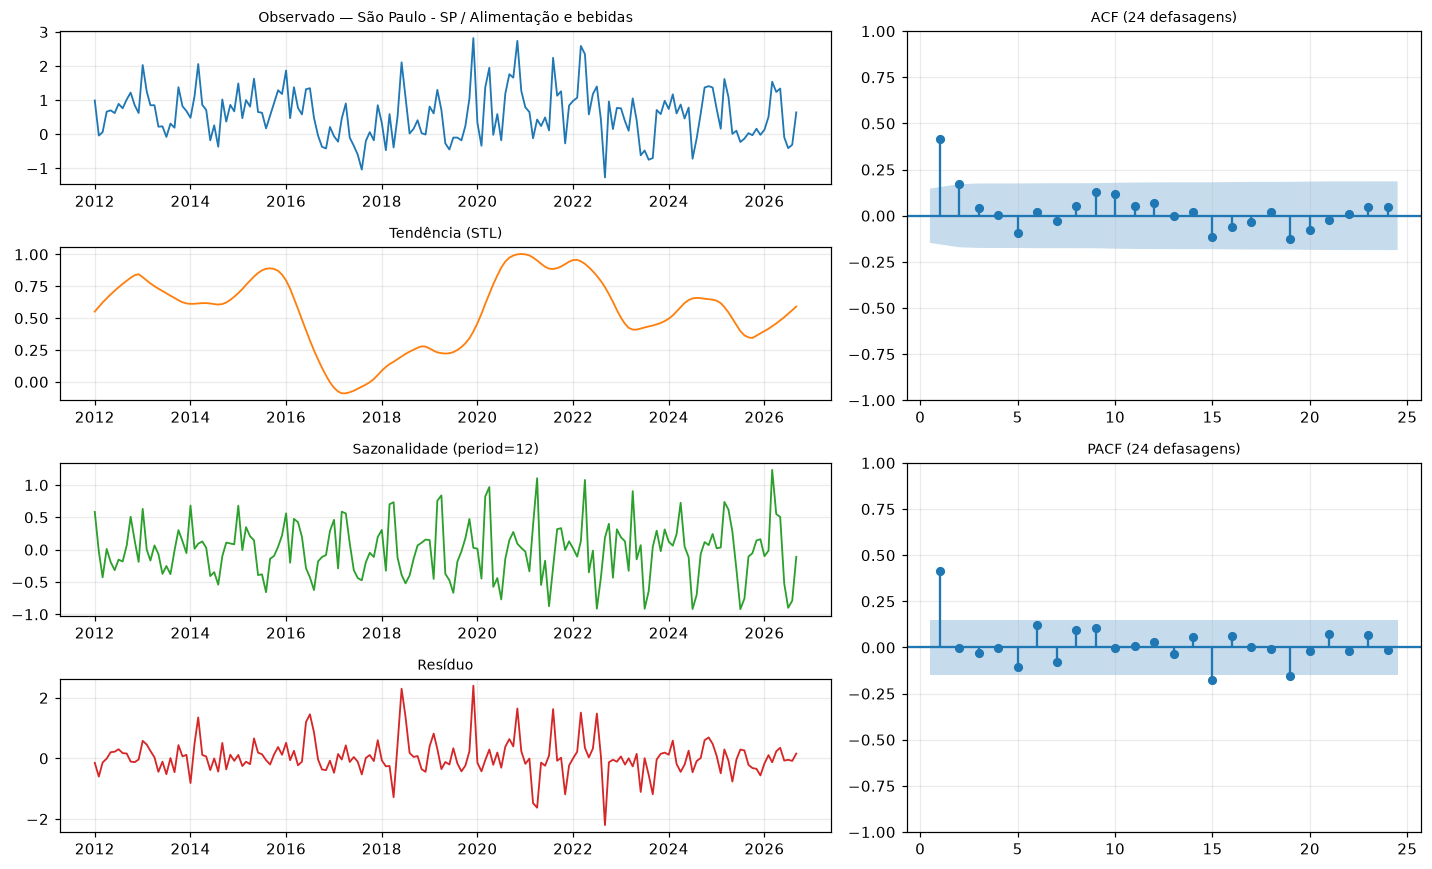

In [5]:
# Decomposição STL e ACF/PACF dinâmicos para (AREA_EXEMPLO, GRUPO_EXEMPLO)
sub_eda = (
    painel.loc[(painel["area"] == AREA_EXEMPLO) & (painel["grupo_despesa"] == GRUPO_EXEMPLO), ["data", "variacao_ipca_mensal_pct"]]
    .dropna()
    .sort_values("data")
    .set_index("data")["variacao_ipca_mensal_pct"]
)

stl_res = STL(sub_eda, period=12, robust=True).fit()
adf_p = adfuller(sub_eda, autolag="AIC")[1]
kpss_p = kpss(sub_eda, regression="c", nlags="auto")[1]
print(f"Série selecionada: {AREA_EXEMPLO} | {GRUPO_EXEMPLO} ({len(sub_eda)} meses) -> ADF p={adf_p:.4f} | KPSS p={kpss_p:.4f}")

fig = plt.figure(figsize=(13, 8))
gs = fig.add_gridspec(4, 2, width_ratios=[1.5, 1])

for i, (comp, title, color) in enumerate(
    [
        (sub_eda, f"Observado — {AREA_EXEMPLO} / {GRUPO_EXEMPLO}", "tab:blue"),
        (stl_res.trend, "Tendência (STL)", "tab:orange"),
        (stl_res.seasonal, "Sazonalidade (period=12)", "tab:green"),
        (stl_res.resid, "Resíduo", "tab:red"),
    ]
):
    ax = fig.add_subplot(gs[i, 0])
    ax.plot(comp.index, comp.values, color=color, linewidth=1.2)
    ax.set_title(title, fontsize=9)
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))

ax_acf = fig.add_subplot(gs[0:2, 1])
plot_acf(sub_eda, lags=24, ax=ax_acf, zero=False)
ax_acf.set_title("ACF (24 defasagens)", fontsize=9)

ax_pacf = fig.add_subplot(gs[2:4, 1])
plot_pacf(sub_eda, lags=24, ax=ax_pacf, method="ywm", zero=False)
ax_pacf.set_title("PACF (24 defasagens)", fontsize=9)

plt.tight_layout()
plt.show()

## 3. Análise de Correlação, CCF, Causalidade de Granger e VIF (Etapa 2)

Avalia correlação de Pearson e Spearman, correlação cruzada defasada (CCF), causalidade de Granger e fator de inflação da variância (VIF com constante em nível e em primeira diferença), finalizando com a **conclusão obrigatória** de quais variáveis e defasagens entram nos modelos.


In [6]:
FEATURES_EXOG = ["selic_efetiva_aa", "cambio_usd_brl", "ic_br", "ibc_br_sa", "desocupacao", "ipca_brasil"]

ipca_med = (
    painel.groupby("data", as_index=False)["variacao_ipca_mensal_pct"]
    .median()
    .rename(columns={"variacao_ipca_mensal_pct": "ipca_mensal_median"})
    .merge(macro, on="data", how="inner")
    .sort_values("data")
    .reset_index(drop=True)
)

if REEXECUTAR_ANALISE_CORRELACAO:
    cols_corr = ["ipca_mensal_median", *FEATURES_EXOG]
    pearson_mat = ipca_med[cols_corr].corr(method="pearson").round(4).reset_index().rename(columns={"index": "variavel"})
    spearman_mat = ipca_med[cols_corr].corr(method="spearman").round(4).reset_index().rename(columns={"index": "variavel"})
    selecao_ccf = pd.read_csv(DATA_DIR / "selecao_variaveis_correlacao.csv", encoding="utf-8-sig")

    granger_rows = []
    for feat in FEATURES_EXOG:
        sub_g = ipca_med[["ipca_mensal_median", feat]].dropna()
        res_g = grangercausalitytests(sub_g, maxlag=MAX_LAG_GRANGER)
        for lag in range(1, MAX_LAG_GRANGER + 1):
            granger_rows.append(
                {
                    "variavel_exogena": feat,
                    "defasagem_meses": lag,
                    "f_stat_nacional": float(res_g[lag][0]["ssr_ftest"][0]),
                    "p_valor_nacional": float(res_g[lag][0]["ssr_ftest"][1]),
                    "significativo_nacional_5pct": bool(res_g[lag][0]["ssr_ftest"][1] < 0.05),
                }
            )
    granger_df = pd.DataFrame(granger_rows)

    def _calc_vif(df_in: pd.DataFrame, cols: list[str], regime: str) -> list[dict]:
        x_c = sm.add_constant(df_in[cols].dropna(), has_constant="add")
        return [
            {"regime": regime, "variavel_exogena": c, "vif": float(variance_inflation_factor(x_c.to_numpy(dtype=float), i))}
            for i, c in enumerate(x_c.columns)
            if c != "const"
        ]

    vif_df = pd.DataFrame(
        _calc_vif(ipca_med, FEATURES_EXOG, "nivel_todas_variaveis")
        + _calc_vif(ipca_med[FEATURES_EXOG].diff().dropna(), FEATURES_EXOG, "primeira_diferenca_todas")
    )
    conclusao_var = pd.read_csv(DATA_DIR / "conclusao_selecao_variaveis.csv", encoding="utf-8-sig")
else:
    pearson_mat = pd.read_csv(DATA_DIR / "matriz_correlacao_pearson.csv", encoding="utf-8-sig")
    spearman_mat = pd.read_csv(DATA_DIR / "matriz_correlacao_spearman.csv", encoding="utf-8-sig")
    selecao_ccf = pd.read_csv(DATA_DIR / "selecao_variaveis_correlacao.csv", encoding="utf-8-sig")
    granger_df = pd.read_csv(DATA_DIR / "causalidade_granger.csv", encoding="utf-8-sig")
    vif_df = pd.read_csv(DATA_DIR / "vif_variaveis.csv", encoding="utf-8-sig")
    conclusao_var = pd.read_csv(DATA_DIR / "conclusao_selecao_variaveis.csv", encoding="utf-8-sig")

print("Matriz de Correlação de Pearson (Mensal):")
display(pearson_mat)
print("Matriz de Correlação de Spearman (Mensal):")
display(spearman_mat)
print("VIF (Multicolinearidade com constante — nível vs. 1ª diferença):")
display(vif_df.pivot(index="variavel_exogena", columns="regime", values="vif").round(3))
print("Conclusão obrigatória — variáveis e defasagens selecionadas:")
display(conclusao_var)

Matriz de Correlação de Pearson (Mensal):


,variavel,ipca_mensal_median,selic_efetiva_aa,cambio_usd_brl,ic_br,ibc_br_sa,desocupacao,ipca_brasil
0,ipca_mensal_median,1.0000,0.1190,-0.0474,0.0516,0.0553,-0.0786,0.7798
1,selic_efetiva_aa,0.1190,1.0000,0.0501,0.3090,0.4724,-0.6346,-0.0224
2,cambio_usd_brl,-0.0474,0.0501,1.0000,0.8903,0.2507,0.0795,-0.0219
3,ic_br,0.0516,0.3090,0.8903,1.0000,0.5825,-0.2773,0.0038
4,ibc_br_sa,0.0553,0.4724,0.2507,0.5825,1.0000,-0.8322,0.0258
5,desocupacao,-0.0786,-0.6346,0.0795,-0.2773,-0.8322,1.0000,0.0060
6,ipca_brasil,0.7798,-0.0224,-0.0219,0.0038,0.0258,0.0060,1.0000


Matriz de Correlação de Spearman (Mensal):


,variavel,ipca_mensal_median,selic_efetiva_aa,cambio_usd_brl,ic_br,ibc_br_sa,desocupacao,ipca_brasil
0,ipca_mensal_median,1.0000,0.1225,-0.0836,-0.0601,0.0840,-0.0929,0.8226
1,selic_efetiva_aa,0.1225,1.0000,0.0881,0.2704,0.3857,-0.5753,0.0052
2,cambio_usd_brl,-0.0836,0.0881,1.0000,0.9255,0.2259,0.0232,-0.0175
3,ic_br,-0.0601,0.2704,0.9255,1.0000,0.3783,-0.1520,-0.0288
4,ibc_br_sa,0.0840,0.3857,0.2259,0.3783,1.0000,-0.8670,0.0411
5,desocupacao,-0.0929,-0.5753,0.0232,-0.1520,-0.8670,1.0000,-0.0288
6,ipca_brasil,0.8226,0.0052,-0.0175,-0.0288,0.0411,-0.0288,1.0000


VIF (Multicolinearidade com constante — nível vs. 1ª diferença):


regime,nivel_sem_ic_br,nivel_todas_variaveis,primeira_diferenca_todas
variavel_exogena,,,
cambio_usd_brl,1.623,12.440,1.623
desocupacao,6.453,6.553,1.060
ibc_br_sa,5.218,7.690,1.150
ic_br,NaN,17.420,1.456
ipca_brasil,NaN,1.013,1.061
selic_efetiva_aa,1.807,2.083,1.061


Conclusão obrigatória — variáveis e defasagens selecionadas:


,variavel_exogena,entra_no_modelo,melhor_lag_ccf,top3_lags_ccf_positivos,lags_granger_sig_nacional,granger_min_p_nacional,granger_max_prop_painel_5pct,vif_nivel,vif_diferenca,defasagens_recomendadas,justificativa
0,selic_efetiva_aa,True,2,"2,3,4","3,5",0.0370,0.3889,2.083,1.061,"1, 3, 6, 12 (ou 1..6 no VAR)",VIF em diferença=1.06 (<5); CCF máxima no lag ...
1,cambio_usd_brl,True,1,"1,4,3",nenhum,0.1627,0.1111,12.440,1.623,"1, 3, 6, 12 (ou 1..6 no VAR)",VIF em diferença=1.62 (<5); CCF máxima no lag ...
2,ic_br,True,11,"11,12,10",nenhum,0.0595,0.1667,17.420,1.456,"1, 3, 6, 12 (ou 1..6 no VAR)",VIF em diferença=1.46 (<5); CCF máxima no lag ...
3,ibc_br_sa,True,4,"4,3,12",nenhum,0.1245,0.1319,7.690,1.150,"1, 3, 6, 12 (ou 1..6 no VAR)",VIF em diferença=1.15 (<5); CCF máxima no lag ...
4,desocupacao,True,4,"4,3,5",nenhum,0.5577,0.4583,6.553,1.060,"1, 3, 6, 12 (ou 1..6 no VAR)",VIF em diferença=1.06 (<5); CCF máxima no lag ...
5,ipca_brasil,False,0,"1,2,10","1,2,4,5,6",0.0082,0.3819,1.013,1.061,não se aplica,Série agregada nacional do próprio alvo (IPCA)...


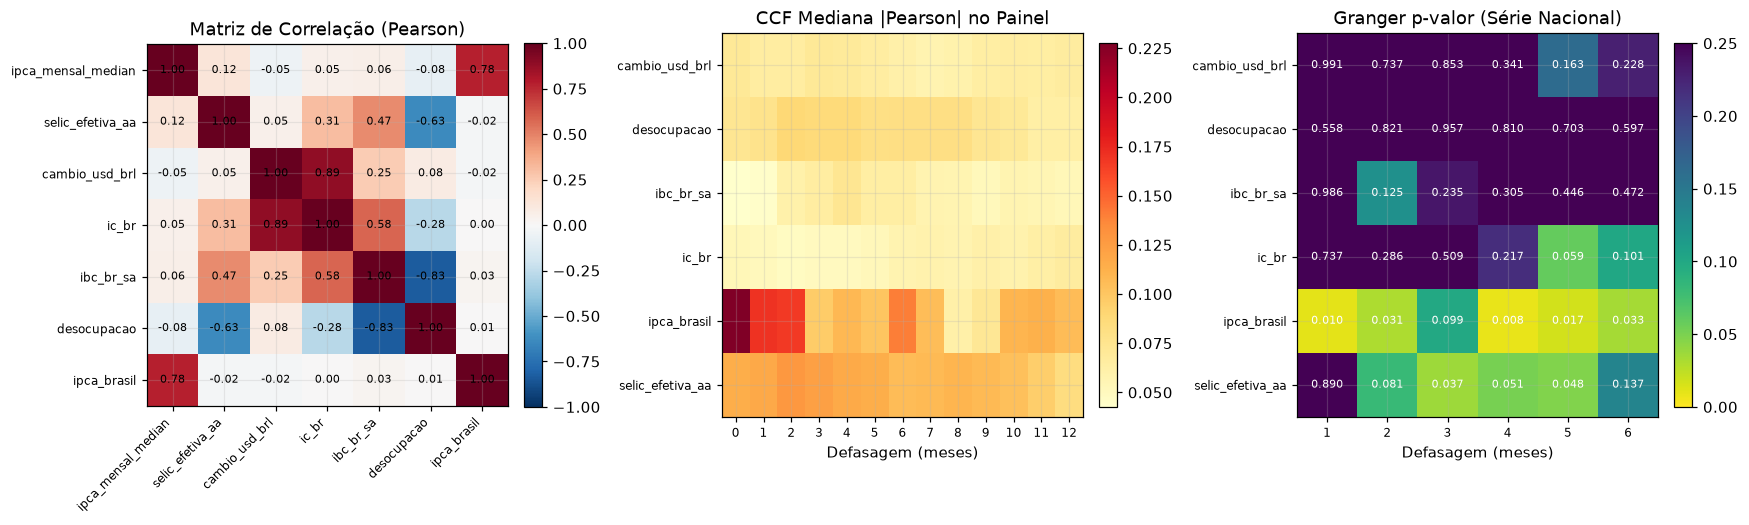

In [7]:
# Visualização da Matriz de Pearson, CCF por defasagem e p-valores de Granger
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))

p_idx = pearson_mat.set_index("variavel")
im0 = axes[0].imshow(p_idx.to_numpy(dtype=float), cmap="RdBu_r", vmin=-1, vmax=1)
axes[0].set_xticks(range(len(p_idx.columns)))
axes[0].set_xticklabels(p_idx.columns, rotation=45, ha="right", fontsize=8)
axes[0].set_yticks(range(len(p_idx.index)))
axes[0].set_yticklabels(p_idx.index, fontsize=8)
axes[0].set_title("Matriz de Correlação (Pearson)")
for i in range(len(p_idx.index)):
    for j in range(len(p_idx.columns)):
        axes[0].text(j, i, f"{p_idx.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7)
fig.colorbar(im0, ax=axes[0], fraction=0.046, pad=0.04)

piv_ccf = selecao_ccf.pivot(index="variavel_exogena", columns="defasagem_meses", values="mediana_abs_pearson")
im1 = axes[1].imshow(piv_ccf.to_numpy(dtype=float), cmap="YlOrRd", aspect="auto")
axes[1].set_xticks(range(len(piv_ccf.columns)))
axes[1].set_xticklabels(piv_ccf.columns, fontsize=8)
axes[1].set_yticks(range(len(piv_ccf.index)))
axes[1].set_yticklabels(piv_ccf.index, fontsize=8)
axes[1].set_xlabel("Defasagem (meses)")
axes[1].set_title("CCF Mediana |Pearson| no Painel")
fig.colorbar(im1, ax=axes[1], fraction=0.046, pad=0.04)

piv_g = granger_df.pivot(index="variavel_exogena", columns="defasagem_meses", values="p_valor_nacional")
im2 = axes[2].imshow(piv_g.to_numpy(dtype=float), cmap="viridis_r", vmin=0, vmax=0.25, aspect="auto")
axes[2].set_xticks(range(len(piv_g.columns)))
axes[2].set_xticklabels(piv_g.columns, fontsize=8)
axes[2].set_yticks(range(len(piv_g.index)))
axes[2].set_yticklabels(piv_g.index, fontsize=8)
axes[2].set_xlabel("Defasagem (meses)")
axes[2].set_title("Granger p-valor (Série Nacional)")
for i in range(len(piv_g.index)):
    for j in range(len(piv_g.columns)):
        axes[2].text(j, i, f"{piv_g.iloc[i, j]:.3f}", ha="center", va="center", color="white", fontsize=7)
fig.colorbar(im2, ax=axes[2], fraction=0.046, pad=0.04)

plt.tight_layout()
plt.show()

## 4. Predição Multivariada e Validação Walk-Forward $h = 1, 2, 3$ (Etapas 3 e 4)

Compara **4 famílias de modelos + Focus** em validação temporal **walk-forward (origem móvel)** sem embaralhamento sobre os últimos 12 meses (`2025-10` a `2026-09`) nos horizontes **$h = 1, 2, 3$ meses**:
- **Referência:** Mediana Focus (`focus_mediana`) e Naïve Sazonal (`baseline_naive_sazonal`).
- **Estatísticos/Lineares:** VAR(4) em diferenças macro, SARIMAX(1,0,1)(1,0,0,12) com exógenas defasadas e Regressão Ridge.
- **Aprendizado de Máquina:** Random Forest com defasagens e janelas móveis.
- **Rede Neural:** LSTM multivariado em PyTorch.
- **Painel completo (`16 áreas × 9 grupos`):** `ridge_painel`, `random_forest_painel` e `baseline_naive_sazonal_painel`.


In [8]:
EXOG_MODELO = ["selic_efetiva_aa", "cambio_usd_brl", "ic_br", "ibc_br_sa", "desocupacao"]


class NotebookLSTM(nn.Module):
    def __init__(self, input_size: int, hidden_size: int = 16) -> None:
        super().__init__()
        self.lstm = nn.LSTM(input_size=input_size, hidden_size=hidden_size, batch_first=True)
        self.output = nn.Linear(hidden_size, 1)

    def forward(self, inputs: torch.Tensor) -> torch.Tensor:
        seq, _ = self.lstm(inputs)
        return self.output(seq[:, -1, :]).squeeze(-1)


def calcular_metricas(actual: pd.Series | np.ndarray, predicted: pd.Series | np.ndarray, naive_scale: float | None = None) -> dict[str, float]:
    y_true = np.asarray(actual, dtype=float)
    y_pred = np.asarray(predicted, dtype=float)
    mask = np.isfinite(y_true) & np.isfinite(y_pred)
    y_true, y_pred = y_true[mask], y_pred[mask]
    err = y_true - y_pred
    mae = float(np.mean(np.abs(err)))
    rmse = float(np.sqrt(np.mean(err ** 2)))
    mape = float(np.mean(np.abs(err) / np.clip(np.abs(y_true), 1e-6, None)) * 100.0)
    smape = float(np.mean(2.0 * np.abs(err) / np.clip(np.abs(y_true) + np.abs(y_pred), 1e-6, None)) * 100.0)
    denom = naive_scale if naive_scale and naive_scale > 0 else float(np.mean(np.abs(np.diff(y_true))))
    mase = float(mae / denom) if denom > 0 else np.nan
    return {"mae": mae, "rmse": rmse, "mape_pct": mape, "smape_pct": smape, "mase": mase}


def executar_walk_forward_live(df_base: pd.DataFrame, focus_df: pd.DataFrame) -> tuple[pd.DataFrame, pd.DataFrame, pd.DataFrame]:
    work = df_base.copy()
    for lag in [1, 3, 6, 12]:
        work[f"ipca_lag_{lag}"] = work["ipca_mensal_median"].shift(lag)
        for f in EXOG_MODELO:
            work[f"{f}_lag_{lag}"] = work[f].shift(lag)
    work["ipca_mm_3m"] = work["ipca_mensal_median"].rolling(3).mean()
    work["ipca_mm_6m"] = work["ipca_mensal_median"].rolling(6).mean()
    work["ipca_std_3m"] = work["ipca_mensal_median"].rolling(3).std()
    for f in EXOG_MODELO:
        work[f"{f}_diff1"] = work[f].diff(1)
        work[f"{f}_mm_3m"] = work[f].rolling(3).mean()

    feat_cols = [
        "ipca_mensal_median", "ipca_mm_3m", "ipca_mm_6m", "ipca_std_3m",
        *EXOG_MODELO, *[f"{f}_diff1" for f in EXOG_MODELO], *[f"{f}_mm_3m" for f in EXOG_MODELO],
        *[f"ipca_lag_{l}" for l in (1, 3, 6, 12)],
        *[f"{f}_lag_{l}" for l in (1, 3, 6, 12) for f in EXOG_MODELO],
    ]
    focus_b0 = focus_df.loc[focus_df["base_calculo"] == 0].copy()
    focus_b0["origem_mes"] = focus_b0["data_coleta"].dt.to_period("M").dt.to_timestamp()
    focus_b0 = focus_b0.sort_values("data_coleta").drop_duplicates(["origem_mes", "mes_referencia"], keep="last")
    focus_map = focus_b0.set_index(["origem_mes", "mes_referencia"])["mediana_pct"].to_dict()

    split_idx = len(work) - MESES_TESTE
    naive_scale = float(np.mean(np.abs(work.iloc[:split_idx]["ipca_mensal_median"].diff(12).dropna())))

    # Treino único do LSTM na janela pré-teste e previsão recursiva walk-forward
    lstm_cols = ["ipca_mensal_median", *EXOG_MODELO]
    clean = work[["data", *lstm_cols]].dropna().reset_index(drop=True)
    split_date = work.iloc[split_idx]["data"]
    tr_vals = clean.loc[clean["data"] < split_date, lstm_cols].to_numpy(dtype=np.float32)
    all_vals = clean[lstm_cols].to_numpy(dtype=np.float32)
    mu, sd = tr_vals.mean(axis=0), np.where(tr_vals.std(axis=0) == 0, 1.0, tr_vals.std(axis=0))
    scaled = (all_vals - mu) / sd
    n_tr = len(tr_vals)
    seqs = np.stack([scaled[i - LSTM_LOOKBACK : i] for i in range(LSTM_LOOKBACK, n_tr)])
    lbls = scaled[LSTM_LOOKBACK:n_tr, 0]
    torch.manual_seed(42)
    net = NotebookLSTM(len(lstm_cols))
    opt = torch.optim.Adam(net.parameters(), lr=0.01)
    for _ in range(LSTM_EPOCHS):
        opt.zero_grad()
        loss = nn.MSELoss()(net(torch.as_tensor(seqs, dtype=torch.float32)), torch.as_tensor(lbls, dtype=torch.float32))
        loss.backward()
        opt.step()
    net.eval()
    date_idx = {d: i for i, d in enumerate(work["data"])}
    lstm_map = {}
    with torch.no_grad():
        for c_orig in range(n_tr - 1, len(clean) - 1):
            o_idx = date_idx[clean.iloc[c_orig]["data"]]
            win = scaled[c_orig - LSTM_LOOKBACK + 1 : c_orig + 1].copy()
            for h in HORIZONTES:
                if o_idx + h < len(work):
                    p_sc = float(net(torch.as_tensor(win[None, :, :], dtype=torch.float32)).item())
                    lstm_map[(o_idx, h)] = p_sc * float(sd[0]) + float(mu[0])
                    nxt = win[-1].copy()
                    nxt[0] = p_sc
                    win = np.vstack([win[1:], nxt])

    rows = []
    for o_idx in range(split_idx - 1, len(work) - 1):
        o_date = work.iloc[o_idx]["data"]
        tr_slice = work.iloc[: o_idx + 1]
        var_preds, sar_preds = {}, {}
        v_frame = tr_slice[["ipca_mensal_median", *[f"{f}_diff1" for f in EXOG_MODELO]]].dropna()
        if len(v_frame) >= 36:
            v_fit = VAR(v_frame).fit(4)
            v_fc = v_fit.forecast(y=v_frame.tail(v_fit.k_ar).to_numpy(dtype=float), steps=max(HORIZONTES))
            var_preds = {h: float(v_fc[h - 1, 0]) for h in HORIZONTES}
        s_cols = [f"{f}_lag_1" for f in EXOG_MODELO]
        s_frame = tr_slice[["ipca_mensal_median", *s_cols]].dropna()
        if len(s_frame) >= 36:
            s_fit = SARIMAX(s_frame["ipca_mensal_median"], exog=s_frame[s_cols], order=(1, 0, 1), seasonal_order=(1, 0, 0, 12), enforce_stationarity=False, enforce_invertibility=False).fit(disp=False)
            ex_rep = np.repeat(work.iloc[[o_idx]][EXOG_MODELO].to_numpy(dtype=float), repeats=max(HORIZONTES), axis=0)
            s_fc = s_fit.forecast(steps=max(HORIZONTES), exog=ex_rep)
            sar_preds = {h: float(s_fc.iloc[h - 1]) for h in HORIZONTES}

        for h in HORIZONTES:
            t_idx = o_idx + h
            if t_idx >= len(work):
                continue
            t_date = work.iloc[t_idx]["data"]
            y_obs = float(work.iloc[t_idx]["ipca_mensal_median"])
            direct = tr_slice[feat_cols].copy()
            direct["y"] = tr_slice["ipca_mensal_median"].shift(-h)
            direct = direct.dropna()
            x_te = work.iloc[[o_idx]][feat_cols].to_numpy(dtype=float)
            ridge_m = make_pipeline(StandardScaler(), Ridge(alpha=ALPHA_RIDGE)).fit(direct[feat_cols].to_numpy(dtype=float), direct["y"].to_numpy(dtype=float))
            rf_m = RandomForestRegressor(n_estimators=RF_N_ESTIMATORS, max_depth=RF_MAX_DEPTH, min_samples_leaf=3, random_state=42, n_jobs=-1).fit(direct[feat_cols].to_numpy(dtype=float), direct["y"].to_numpy(dtype=float))
            preds_h = {
                "baseline_naive_sazonal": float(work.iloc[t_idx - 12]["ipca_mensal_median"]),
                "focus_mediana": float(focus_map.get((o_date, t_date), np.nan)),
                "regressao_ridge": float(ridge_m.predict(x_te)[0]),
                "random_forest": float(rf_m.predict(x_te)[0]),
                "var_multivariado": var_preds.get(h, np.nan),
                "sarimax_exogeno": sar_preds.get(h, np.nan),
                "lstm_multivariado": lstm_map.get((o_idx, h), np.nan),
            }
            for m_name, p_val in preds_h.items():
                rows.append({"modelo": m_name, "data_origem": o_date, "data_alvo": t_date, "horizonte_meses": h, "observado": y_obs, "previsto": p_val, "erro": y_obs - p_val})

    wf = pd.DataFrame(rows).sort_values(["modelo", "horizonte_meses", "data_alvo"]).reset_index(drop=True)
    ev_all = pd.DataFrame([{"modelo": m, "n_previsoes": int(g["previsto"].notna().sum()), **calcular_metricas(g["observado"], g["previsto"], naive_scale)} for m, g in wf.groupby("modelo")]).sort_values("rmse")
    ev_h = pd.DataFrame([{"modelo": m, "horizonte_meses": h, "n_previsoes": int(g["previsto"].notna().sum()), **calcular_metricas(g["observado"], g["previsto"], naive_scale)} for (m, h), g in wf.groupby(["modelo", "horizonte_meses"])]).sort_values(["horizonte_meses", "rmse"])
    return wf, ev_all, ev_h


if REEXECUTAR_MODELAGEM:
    print("Executando walk-forward ao vivo com os hiperparâmetros configurados...")
    wf_df, aval_modelos, aval_horizonte = executar_walk_forward_live(ipca_med, focus)
else:
    wf_df = pd.read_csv(DATA_DIR / "previsoes_walk_forward.csv", parse_dates=["data_origem", "data_alvo"], encoding="utf-8-sig")
    aval_modelos = pd.read_csv(DATA_DIR / "avaliacao_modelos.csv", encoding="utf-8-sig")
    aval_horizonte = pd.read_csv(DATA_DIR / "avaliacao_modelos_por_horizonte.csv", encoding="utf-8-sig")

aval_painel = pd.read_csv(DATA_DIR / "avaliacao_painel_area_grupo.csv", encoding="utf-8-sig")
prev_painel = pd.read_csv(DATA_DIR / "previsoes_painel_area_grupo.csv", parse_dates=["data_origem", "data_alvo"], encoding="utf-8-sig")

print("Avaliação Consolidada (Walk-Forward h=1,2,3 meses — Série Nacional):")
display(aval_modelos.round(4))
print("Avaliação por Horizonte (h=1, 2 e 3 meses):")
display(aval_horizonte.round(4))
print("Avaliação no Painel Desagregado (16 áreas × 9 grupos):")
display(aval_painel.round(4))

Avaliação Consolidada (Walk-Forward h=1,2,3 meses — Série Nacional):


,modelo,protocolo,n_previsoes,periodo_teste_inicio,periodo_teste_fim,mae,rmse,mape_pct,smape_pct,mase
0,focus_mediana,"walk-forward origem móvel (h=1,2,3)",33,2025-10-01,2026-09-01,0.1351,0.1526,123.4526,58.4519,0.7168
1,baseline_naive_sazonal,"walk-forward origem móvel (h=1,2,3)",33,2025-10-01,2026-09-01,0.1391,0.1837,84.0762,53.6244,0.7382
2,var_multivariado,"walk-forward origem móvel (h=1,2,3)",33,2025-10-01,2026-09-01,0.1734,0.1914,128.1985,73.3408,0.9202
3,sarimax_exogeno,"walk-forward origem móvel (h=1,2,3)",33,2025-10-01,2026-09-01,0.1731,0.1918,136.0644,72.4551,0.9188
4,regressao_ridge,"walk-forward origem móvel (h=1,2,3)",33,2025-10-01,2026-09-01,0.1737,0.2042,105.7098,73.2061,0.9220
5,random_forest,"walk-forward origem móvel (h=1,2,3)",33,2025-10-01,2026-09-01,0.1798,0.2062,139.5728,70.7956,0.9544
6,lstm_multivariado,"walk-forward origem móvel (h=1,2,3)",32,2025-10-01,2026-09-01,0.1965,0.2751,85.7198,93.3850,1.0427


Avaliação por Horizonte (h=1, 2 e 3 meses):


,modelo,horizonte_meses,n_previsoes,mae,rmse,mape_pct,smape_pct,mase
0,focus_mediana,1,12,0.1420,0.1625,196.1581,68.8350,0.7535
1,var_multivariado,1,12,0.1478,0.1711,124.5130,70.4538,0.7846
2,sarimax_exogeno,1,12,0.1526,0.1719,137.4589,74.4328,0.8098
3,random_forest,1,12,0.1548,0.1764,121.9347,69.6389,0.8218
4,regressao_ridge,1,12,0.1534,0.1882,109.9122,70.5033,0.8142
5,baseline_naive_sazonal,1,12,0.1508,0.2007,154.5831,60.0830,0.8005
6,lstm_multivariado,1,11,0.2040,0.2812,125.1036,110.3366,1.0824
7,focus_mediana,2,11,0.1382,0.1517,113.3502,65.3512,0.7333
8,baseline_naive_sazonal,2,11,0.1273,0.1693,44.3937,49.6843,0.6754
9,var_multivariado,2,11,0.1733,0.1947,120.2751,74.6809,0.9198


Avaliação no Painel Desagregado (16 áreas × 9 grupos):


,modelo,horizonte_meses,n_previsoes,n_areas,n_grupos,mae,rmse,mape_pct,smape_pct,mase
0,ridge_painel,1,1728,16,9,0.5956,0.9070,329854.8571,119.2710,0.7157
1,random_forest_painel,1,1728,16,9,0.6071,0.9095,327615.2407,124.9439,0.7296
2,baseline_naive_sazonal_painel,1,1728,16,9,0.6713,1.0602,375310.0377,117.0789,0.8067
3,ridge_painel,2,1584,16,9,0.6037,0.9316,172327.3006,122.7739,0.7005
4,random_forest_painel,2,1584,16,9,0.6080,0.9397,172857.7938,131.5064,0.7055
5,baseline_naive_sazonal_painel,2,1584,16,9,0.6700,1.0683,316581.4805,115.7182,0.7774
6,ridge_painel,3,1440,16,9,0.6001,0.9445,134526.3319,119.8943,0.7053
7,random_forest_painel,3,1440,16,9,0.6377,0.9725,233377.2398,117.6854,0.7496
8,baseline_naive_sazonal_painel,3,1440,16,9,0.6515,1.0462,57917.6275,114.2668,0.7657


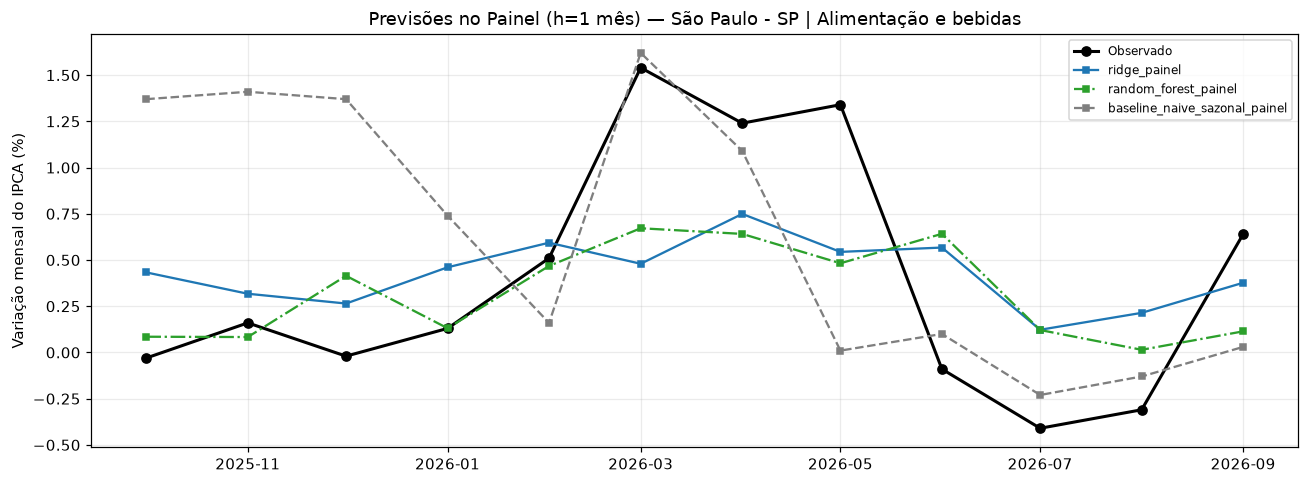

In [9]:
# Previsão no Painel para a unidade configurada (AREA_EXEMPLO × GRUPO_EXEMPLO) em h = 1 mês
sub_p = prev_painel.loc[
    (prev_painel["area"] == AREA_EXEMPLO)
    & (prev_painel["grupo_despesa"] == GRUPO_EXEMPLO)
    & (prev_painel["horizonte_meses"] == 1)
].sort_values("data_alvo")

fig, ax = plt.subplots(figsize=(12, 4.5))
obs_p = sub_p.drop_duplicates("data_alvo")
ax.plot(obs_p["data_alvo"], obs_p["observado"], color="black", linewidth=2, marker="o", label="Observado")
for mod_name, cor, ls in [
    ("ridge_painel", "tab:blue", "-"),
    ("random_forest_painel", "tab:green", "-."),
    ("baseline_naive_sazonal_painel", "tab:gray", "--"),
]:
    s_m = sub_p.loc[sub_p["modelo"] == mod_name]
    ax.plot(s_m["data_alvo"], s_m["previsto"], color=cor, linestyle=ls, marker="s", markersize=4, label=mod_name)

ax.set_title(f"Previsões no Painel (h=1 mês) — {AREA_EXEMPLO} | {GRUPO_EXEMPLO}")
ax.set_ylabel("Variação mensal do IPCA (%)")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
ax.legend(loc="best", fontsize=8)
plt.tight_layout()
plt.show()

## 5. Métricas de Avaliação, Teste de Diebold-Mariano e Intervalos de Previsão (Etapa 5)

Visualiza comparativamente MAE, RMSE, sMAPE e MASE, apresenta os resultados do teste estatístico de **Diebold-Mariano** (`teste_diebold_mariano.csv`) e exibe os **intervalos de previsão empíricos de 80% e 95%**.


Teste Bilateral de Diebold-Mariano (H0: igualdade de precisão preditiva):


,modelo_1,modelo_2,horizonte_meses,n_pares,dm_stat_mse,p_valor_mse,dm_stat_mae,p_valor_mae
0,var_multivariado,sarimax_exogeno,1,12,-0.0433,0.9662,-0.2924,0.7754
1,var_multivariado,sarimax_exogeno,2,11,-0.1075,0.9165,-0.0907,0.9295
2,var_multivariado,sarimax_exogeno,3,10,0.1343,0.8961,0.6254,0.5472
3,var_multivariado,focus_mediana,1,12,0.2468,0.8096,0.1680,0.8697
4,var_multivariado,focus_mediana,2,11,1.6649,0.1269,1.0944,0.2995
5,var_multivariado,focus_mediana,3,10,1.7628,0.1118,1.7892,0.1072
6,var_multivariado,baseline_naive_sazonal,1,12,-0.5921,0.5657,-0.0654,0.9490
7,var_multivariado,baseline_naive_sazonal,2,11,0.6753,0.5148,1.1277,0.2858
8,var_multivariado,baseline_naive_sazonal,3,10,1.2322,0.2491,2.1310,0.0619


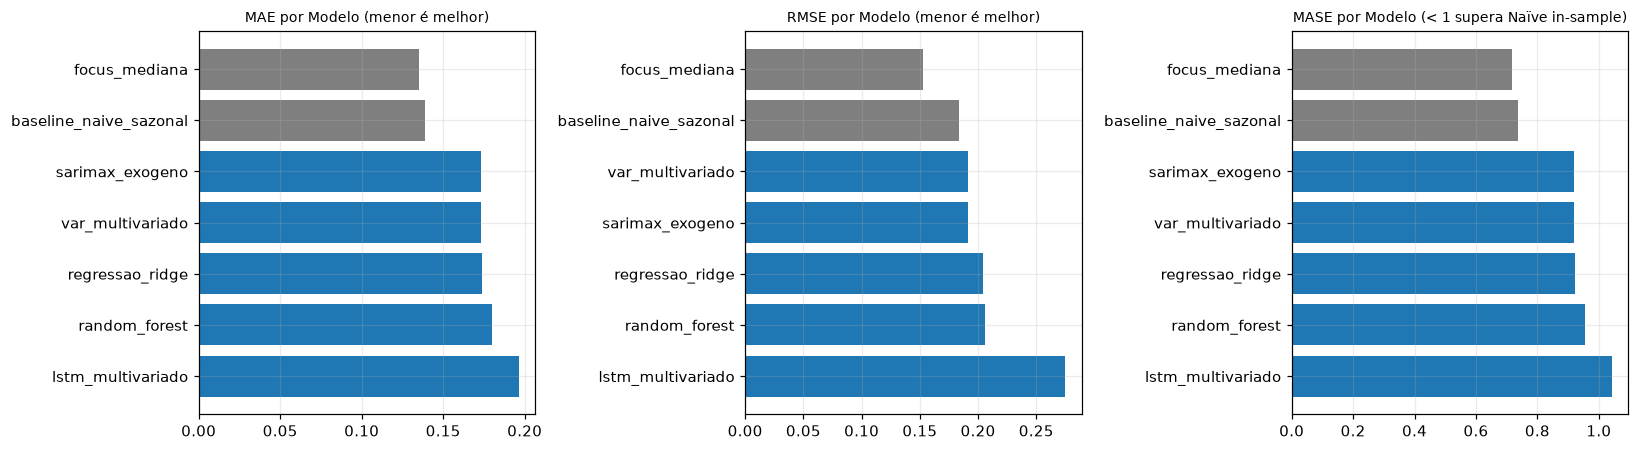

In [10]:
dm_df = pd.read_csv(DATA_DIR / "teste_diebold_mariano.csv", encoding="utf-8-sig")
print("Teste Bilateral de Diebold-Mariano (H0: igualdade de precisão preditiva):")
display(dm_df)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for ax, metrica, titulo in [
    (axes[0], "mae", "MAE por Modelo (menor é melhor)"),
    (axes[1], "rmse", "RMSE por Modelo (menor é melhor)"),
    (axes[2], "mase", "MASE por Modelo (< 1 supera Naïve in-sample)"),
]:
    ordenado = aval_modelos.sort_values(metrica)
    cores = ["tab:gray" if m in {"focus_mediana", "baseline_naive_sazonal"} else "tab:blue" for m in ordenado["modelo"]]
    ax.barh(ordenado["modelo"], ordenado[metrica], color=cores)
    ax.set_title(titulo, fontsize=9)
    ax.invert_yaxis()
plt.tight_layout()
plt.show()

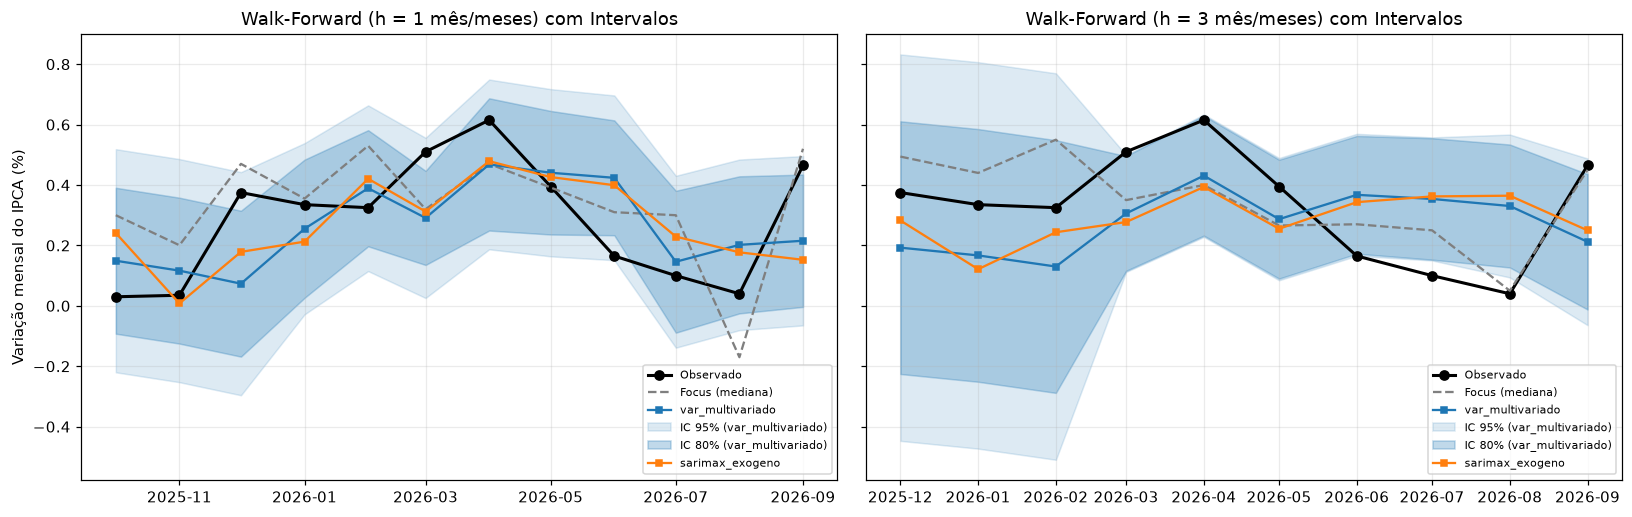

In [11]:
# Intervalos de Previsão (80% e 95%) em h = 1 e h = 3 meses
modelos_proprios = [m for m in aval_modelos["modelo"] if m not in {"focus_mediana", "baseline_naive_sazonal"}][:2]

fig, axes = plt.subplots(1, 2, figsize=(15, 4.8), sharey=True)
for ax, h_plot in zip(axes, [1, 3]):
    sub_h = wf_df.loc[wf_df["horizonte_meses"] == h_plot].copy()
    obs_h = sub_h.drop_duplicates("data_alvo").sort_values("data_alvo")
    ax.plot(obs_h["data_alvo"], obs_h["observado"], color="black", linewidth=2, marker="o", label="Observado")
    foc_h = sub_h.loc[sub_h["modelo"] == "focus_mediana"].sort_values("data_alvo")
    ax.plot(foc_h["data_alvo"], foc_h["previsto"], color="tab:gray", linestyle="--", label="Focus (mediana)")

    for i, mod in enumerate(modelos_proprios):
        s_mod = sub_h.loc[sub_h["modelo"] == mod].sort_values("data_alvo")
        cor = "tab:blue" if i == 0 else "tab:orange"
        ax.plot(s_mod["data_alvo"], s_mod["previsto"], color=cor, marker="s", markersize=4, label=mod)
        if i == 0 and "ic95_inf" in s_mod.columns and s_mod["ic95_inf"].notna().any():
            ax.fill_between(s_mod["data_alvo"], s_mod["ic95_inf"], s_mod["ic95_sup"], color=cor, alpha=0.15, label=f"IC 95% ({mod})")
            ax.fill_between(s_mod["data_alvo"], s_mod["ic80_inf"], s_mod["ic80_sup"], color=cor, alpha=0.28, label=f"IC 80% ({mod})")
    ax.set_title(f"Walk-Forward (h = {h_plot} mês/meses) com Intervalos")
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
    ax.legend(fontsize=7.5, loc="best")

axes[0].set_ylabel("Variação mensal do IPCA (%)")
plt.tight_layout()
plt.show()

## 6. Análise de Sentimento do Copom com LLM e Impacto Preditivo (Etapa 6)

Inspeciona os **238 documentos** do Copom (`documentos_copom.csv`), os **200 rótulos LLM** importados de `rotulo_llm.json`, o cálculo do **kappa de Cohen** contra o método léxico (e contra `rotulacao_manual.csv`, quando preenchida) e o comparativo **SARIMAX sem vs. com sentimento** (`impacto_sentimento_sarimax.csv`).


In [12]:
docs_copom = pd.read_csv(DATA_DIR / "documentos_copom.csv", parse_dates=["data_publicacao"], encoding="utf-8-sig")
trechos = pd.read_csv(DATA_DIR / "trechos_sentimento.csv", encoding="utf-8-sig")
rot_manual = pd.read_csv(DATA_DIR / "rotulacao_manual.csv", encoding="utf-8-sig")
sent_mensal = pd.read_csv(DATA_DIR / "sentimento_mensal.csv", parse_dates=["data"], encoding="utf-8-sig")
impacto_sent = pd.read_csv(DATA_DIR / "impacto_sentimento_sarimax.csv", encoding="utf-8-sig")


def cohen_kappa(s1: pd.Series, s2: pd.Series) -> float:
    df_k = pd.DataFrame({"a": s1, "b": s2}).dropna()
    if df_k.empty:
        return float("nan")
    labels = sorted(set(df_k["a"]) | set(df_k["b"]))
    po = float((df_k["a"] == df_k["b"]).mean())
    pe = sum(float((df_k["a"] == lb).mean()) * float((df_k["b"] == lb).mean()) for lb in labels)
    return (po - pe) / (1.0 - pe) if pe < 1 else float("nan")


classif_llm = trechos.loc[trechos["rotulo_llm"].notna()].copy()
kappa_llm_lex = cohen_kappa(classif_llm["rotulo_llm"], classif_llm["rotulo_lexico"])

print(f"Documentos oficiais do Copom coletados: {len(docs_copom)} ({docs_copom['data_publicacao'].min().date()} a {docs_copom['data_publicacao'].max().date()})")
print(f"Trechos classificados via LLM (rotulo_llm.json): {len(classif_llm)} / {len(trechos)}")
print(f"Distribuição dos rótulos LLM: {classif_llm['rotulo_llm'].value_counts().to_dict()}")
print(f"Kappa de Cohen (LLM vs. Léxico de referência): {kappa_llm_lex:.4f}")

valid_manual = rot_manual["rotulo_manual"].astype("string").fillna("").str.strip().str.lower()
n_man = int(valid_manual.isin({"expansionista", "neutro", "contracionista"}).sum())
print(f"Rótulos humanos preenchidos em rotulacao_manual.csv: {n_man}/200")

print("\nMatriz cruzada LLM vs. Léxico de referência:")
display(pd.crosstab(classif_llm["rotulo_llm"], classif_llm["rotulo_lexico"], margins=True))
print("Impacto do sentimento do Copom no SARIMAX Walk-Forward (h = 1 mês):")
display(impacto_sent.round(4))

Documentos oficiais do Copom coletados: 238 (2012-01-18 a 2026-11-10)
Trechos classificados via LLM (rotulo_llm.json): 200 / 1094
Distribuição dos rótulos LLM: {'neutro': 76, 'contracionista': 76, 'expansionista': 48}
Kappa de Cohen (LLM vs. Léxico de referência): 0.3803
Rótulos humanos preenchidos em rotulacao_manual.csv: 0/200

Matriz cruzada LLM vs. Léxico de referência:


rotulo_lexico,contracionista,expansionista,neutro,All
rotulo_llm,,,,
contracionista,49,11,16,76
expansionista,1,39,8,48
neutro,26,21,29,76
All,76,71,53,200


Impacto do sentimento do Copom no SARIMAX Walk-Forward (h = 1 mês):


,modelo,protocolo,n_previsoes,periodo_teste_inicio,periodo_teste_fim,mae,rmse,mape_pct,smape_pct,mase
0,sarimax_sem_sentimento,"walk-forward, horizonte de 1 mês",12,2025-10-01,2026-09-01,0.1329,0.1668,108.8379,63.0812,0.8674
1,sarimax_com_sentimento,"walk-forward, horizonte de 1 mês",12,2025-10-01,2026-09-01,0.1430,0.1771,116.0297,70.1679,0.9335


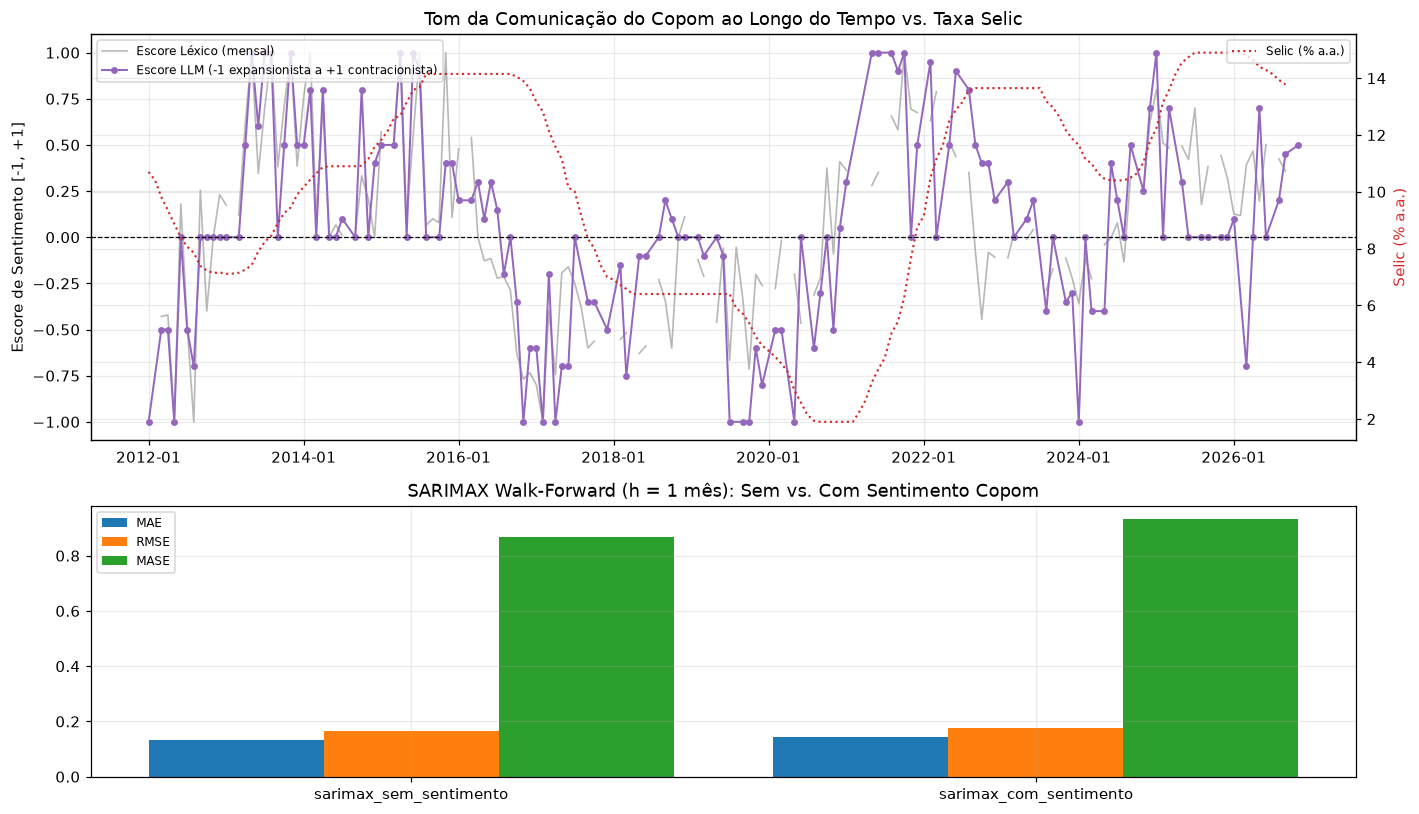

In [13]:
# Série temporal do escore de sentimento do Copom (LLM e Léxico) vs. Selic e impacto no SARIMAX
fig, axes = plt.subplots(2, 1, figsize=(13, 7.5), gridspec_kw={"height_ratios": [1.5, 1]})

s_plot = sent_mensal.sort_values("data")
axes[0].plot(s_plot["data"], s_plot["escore_lexico"], color="tab:gray", alpha=0.55, linewidth=1.1, label="Escore Léxico (mensal)")
llm_obs = s_plot.dropna(subset=["escore_llm"])
axes[0].plot(llm_obs["data"], llm_obs["escore_llm"], color="tab:purple", marker="o", markersize=3.5, linewidth=1.3, label="Escore LLM (-1 expansionista a +1 contracionista)")
axes[0].axhline(0, color="black", linestyle="--", linewidth=0.8)
axes[0].set_ylabel("Escore de Sentimento [-1, +1]")
axes[0].set_title("Tom da Comunicação do Copom ao Longo do Tempo vs. Taxa Selic")
axes[0].xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))

ax_selic = axes[0].twinx()
ax_selic.plot(macro["data"], macro["selic_efetiva_aa"], color="tab:red", linewidth=1.4, linestyle=":", label="Selic (% a.a.)")
ax_selic.set_ylabel("Selic (% a.a.)", color="tab:red")
axes[0].legend(loc="upper left", fontsize=8)
ax_selic.legend(loc="upper right", fontsize=8)

x_pos = np.arange(len(impacto_sent))
w = 0.28
axes[1].bar(x_pos - w, impacto_sent["mae"], width=w, label="MAE")
axes[1].bar(x_pos, impacto_sent["rmse"], width=w, label="RMSE")
axes[1].bar(x_pos + w, impacto_sent["mase"], width=w, label="MASE")
axes[1].set_xticks(x_pos)
axes[1].set_xticklabels(impacto_sent["modelo"])
axes[1].set_title("SARIMAX Walk-Forward (h = 1 mês): Sem vs. Com Sentimento Copom")
axes[1].legend(fontsize=8)

plt.tight_layout()
plt.show()

## 7. Síntese Final e Entregáveis

- **Painel e Dicionários:** `dados/tratados/painel_ipca_macro.csv` (25.488 linhas) + `dicionario_painel_ipca_macro.csv` + `dicionario_variaveis.csv` + `dicionario_sentimento.csv`.
- **Relatório Técnico:** `relatorio_tecnico.md` (metodologia, resultados e limitações).
- **Slides de Apresentação:** `slides_apresentacao.md` (formato Marp).
- **Reprodutibilidade:** todas as saídas deste notebook podem ser recalculadas alterando os parâmetros da **Seção 0** (`AREA_EXEMPLO`, `GRUPO_EXEMPLO`, `REEXECUTAR_ANALISE_CORRELACAO`, `REEXECUTAR_MODELAGEM`).
